**Brain Tumor Detection Using ML and ANN**

**Submitted by:** Syed Shaheer Nasir (F2022266454)
              Zain Ul Abdian (F2022266468)
              Zainab Usman (F2022266828)

This project aims to build an intelligent system that can automatically detect the presence of brain tumors from MRI scans using machine learning (ML) and deep learning techniques. The dataset used consists of grayscale brain MRI images categorized into two classes: 'yes' (tumor) and 'no' (no tumor). Each image was resized to 100×100 pixels, flattened into a 1D vector of 10,000 features, and normalized to bring pixel values into the range [0, 1].

After preprocessing, the dataset was split into 80% training and 20% testing sets. Five classical machine learning models were implemented and trained:

Logistic Regression

Decision Tree

Random Forest

K-Nearest Neighbors (KNN)

Support Vector Machine (SVM)

Each model was evaluated using metrics such as accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC. Visualizations of confusion matrices and ROC curves were also generated to support the analysis.

In addition to classical models, an Artificial Neural Network (ANN) was developed using TensorFlow/Keras. The ANN architecture included two hidden layers (128 and 64 neurons), dropout for regularization, and a final sigmoid output layer for binary classification. The ANN was trained with early stopping to prevent overfitting and validated on 20% of the training data.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/Colab Notebooks/archive.zip'
extract_path = '/content/brain_tumor_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(" Dataset extracted successfully!")


 Dataset extracted successfully!


In [ ]:
import os

data_dir = '/content/brain_tumor_dataset/2 classes'
categories = ['yes', 'no']

for category in categories:
    folder = os.path.join(data_dir, category)
    print(f"{category.upper()}: {len(os.listdir(folder))} images")


YES: 4159 images
NO: 2024 images


Load, Resize, Normalize, Label Images


In [ ]:
import numpy as np
import os
import cv2
from tqdm import tqdm

img_size = 100
data = []
labels = []

data_dir = '/content/brain_tumor_dataset/2 classes'
categories = ['yes', 'no']

for label in categories:
    folder = os.path.join(data_dir, label)
    class_num = 1 if label == 'yes' else 0

    print(f" Loading '{label}' from: {folder}")
    for img_name in tqdm(os.listdir(folder)):
        try:
            img_path = os.path.join(folder, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                print(f"⚠️ Skipped unreadable file: {img_name}")
                continue
            img = cv2.resize(img, (img_size, img_size))
            data.append(img)
            labels.append(class_num)
        except Exception as e:
            print(f" Error reading {img_name}: {e}")

print(" Total images loaded:", len(data))


📂 Loading 'yes' from: /content/brain_tumor_dataset/2 classes/yes


100%|██████████| 4159/4159 [00:02<00:00, 1643.30it/s]


📂 Loading 'no' from: /content/brain_tumor_dataset/2 classes/no


100%|██████████| 2024/2024 [00:01<00:00, 1783.77it/s]

✅ Total images loaded: 6183


In [ ]:
import numpy as np
from tqdm import tqdm  # shows progress bar

img_size = 100  # Resize images to 100x100
data = []
labels = []

for label in categories:  # ['yes', 'no']
    path = os.path.join(data_dir, label)
    class_num = 1 if label == 'yes' else 0

    for img_name in tqdm(os.listdir(path), desc=f"Loading {label}"):
        try:
            img_path = os.path.join(path, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # grayscale
            img = cv2.resize(img, (img_size, img_size))
            data.append(img)
            labels.append(class_num)
        except:
            continue

print(" Done loading all images")


Loading no: 100%|██████████| 2024/2024 [00:00<00:00, 399119.48it/s]

✅ Done loading all images


Convert to NumPy arrays & Normalize

In [ ]:
X = np.array(data).reshape(-1, img_size * img_size)
X = X / 255.0
y = np.array(labels)


 Split into Train & Test Sets

In [ ]:
# Flatten, normalize, split
X = np.array(data).reshape(len(data), -1) / 255.0
y = np.array(labels)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(" Split OK:", X_train.shape, X_test.shape)


✅ Split OK: (4946, 10000) (1237, 10000)



🧠 Logistic Regression
Accuracy: 0.952303961196443
              precision    recall  f1-score   support

           0       0.93      0.92      0.93       405
           1       0.96      0.97      0.96       832

    accuracy                           0.95      1237
   macro avg       0.95      0.94      0.95      1237
weighted avg       0.95      0.95      0.95      1237



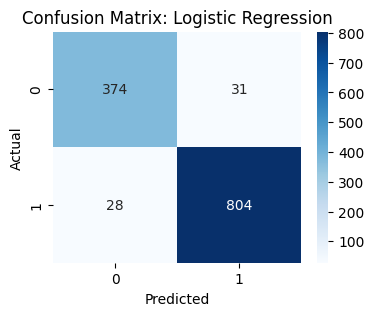


🧠 Decision Tree
Accuracy: 0.8755052546483427
              precision    recall  f1-score   support

           0       0.79      0.85      0.82       405
           1       0.92      0.89      0.91       832

    accuracy                           0.88      1237
   macro avg       0.86      0.87      0.86      1237
weighted avg       0.88      0.88      0.88      1237



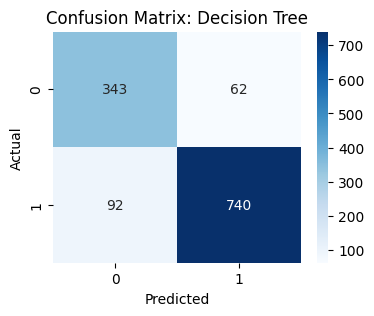


🧠 Random Forest
Accuracy: 0.957962813257882
              precision    recall  f1-score   support

           0       0.97      0.90      0.93       405
           1       0.95      0.98      0.97       832

    accuracy                           0.96      1237
   macro avg       0.96      0.94      0.95      1237
weighted avg       0.96      0.96      0.96      1237



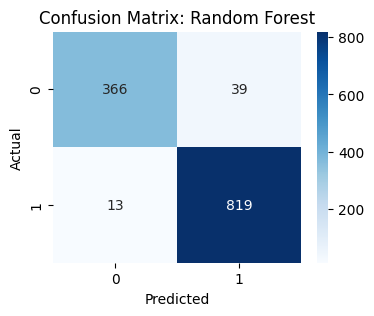


🧠 K-Nearest Neighbors
Accuracy: 0.9037995149555376
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       405
           1       0.95      0.91      0.93       832

    accuracy                           0.90      1237
   macro avg       0.89      0.90      0.89      1237
weighted avg       0.91      0.90      0.90      1237



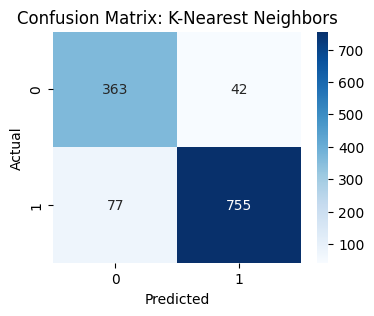


🧠 Support Vector Machine
Accuracy: 0.9482619240097009
              precision    recall  f1-score   support

           0       0.94      0.90      0.92       405
           1       0.95      0.97      0.96       832

    accuracy                           0.95      1237
   macro avg       0.95      0.93      0.94      1237
weighted avg       0.95      0.95      0.95      1237



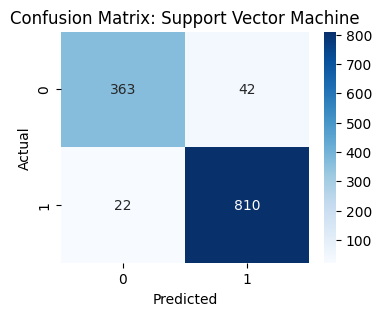

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(n_estimators=100),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(probability=True)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    results[name] = {
        'model': model,
        'accuracy': acc,
        'report': classification_report(y_test, y_pred, output_dict=True),
        'confusion': confusion_matrix(y_test, y_pred)
    }

    print(f"\n {name}")
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))

    # Plot confusion matrix
    plt.figure(figsize=(4,3))
    sns.heatmap(results[name]['confusion'], annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()


Metrics + ROC Curves


📊 Logistic Regression
Accuracy : 0.9523
Precision: 0.9629
Recall   : 0.9663
F1-Score : 0.9646


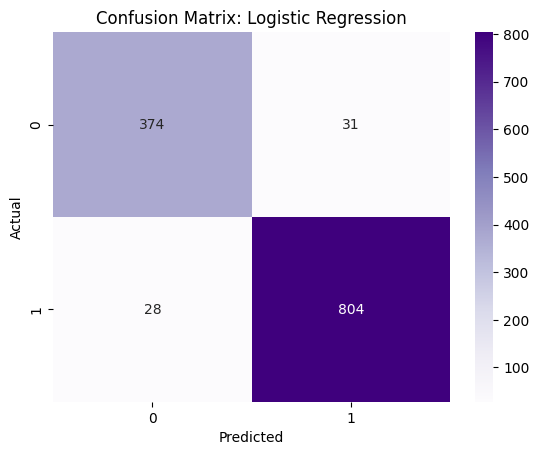

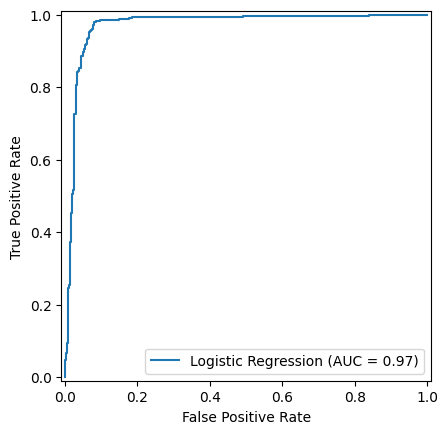


📊 Decision Tree
Accuracy : 0.8755
Precision: 0.9227
Recall   : 0.8894
F1-Score : 0.9058


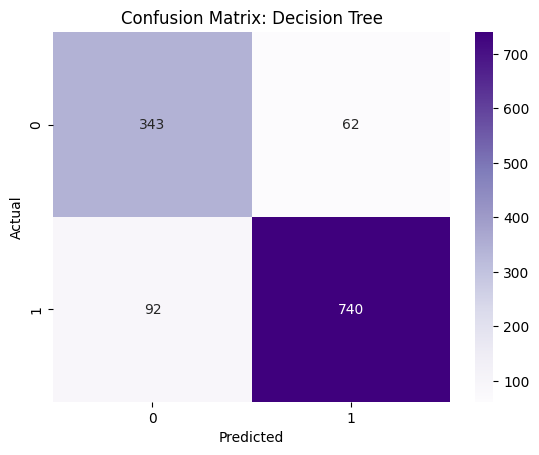

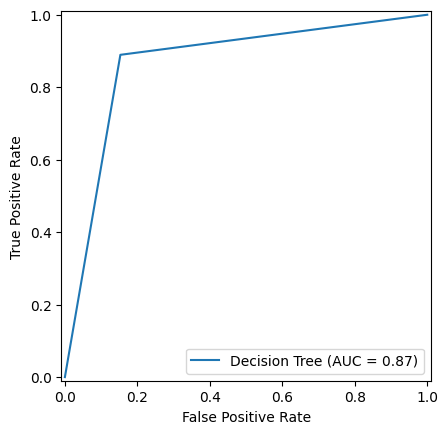


📊 Random Forest
Accuracy : 0.9580
Precision: 0.9545
Recall   : 0.9844
F1-Score : 0.9692


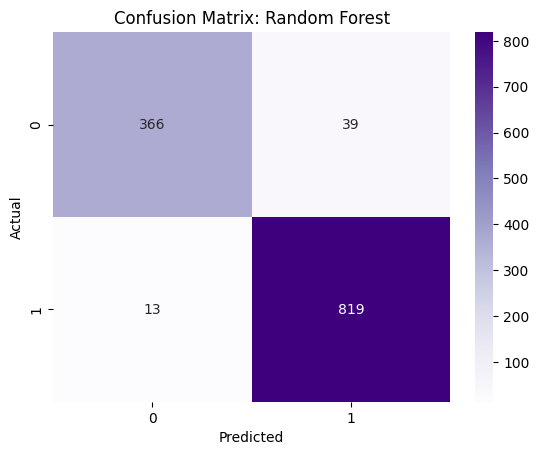

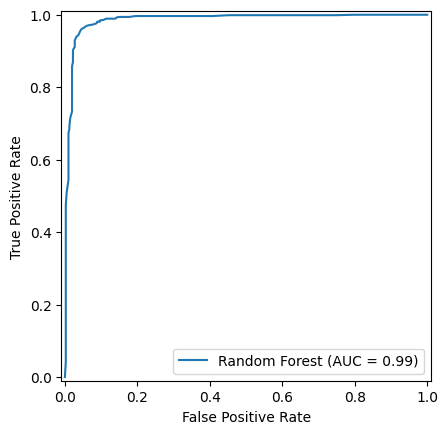


📊 K-Nearest Neighbors
Accuracy : 0.9038
Precision: 0.9473
Recall   : 0.9075
F1-Score : 0.9269


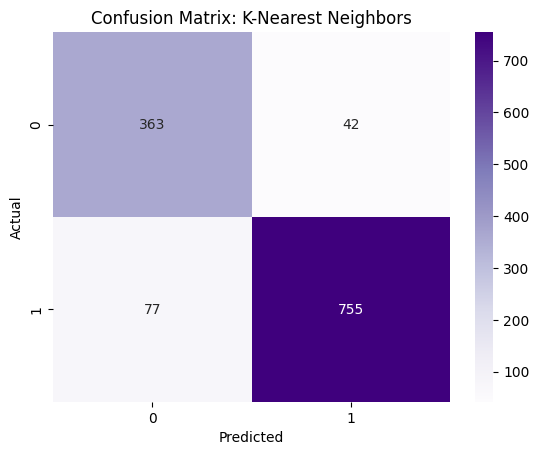

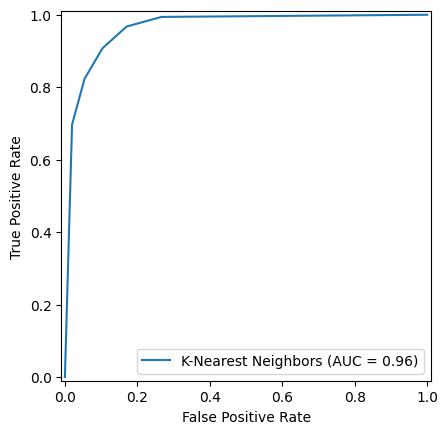


📊 Support Vector Machine
Accuracy : 0.9483
Precision: 0.9507
Recall   : 0.9736
F1-Score : 0.9620


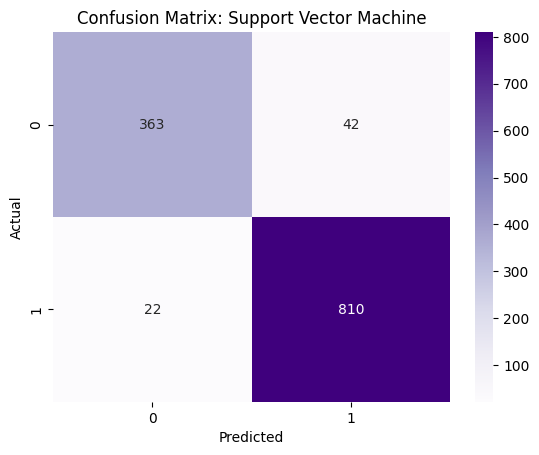

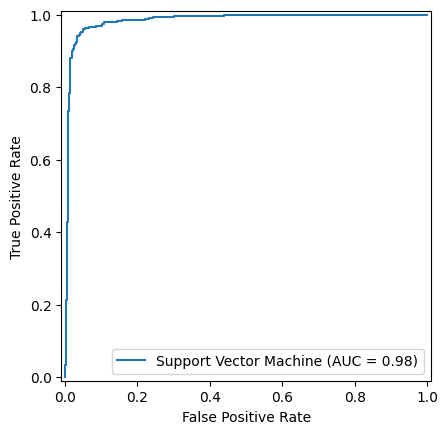

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, auc, RocCurveDisplay)
import matplotlib.pyplot as plt
import seaborn as sns

# For binary classifiers only
def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]  # for ROC

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n {name}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")

    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name=name).plot()
    plt.show()

    return {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'AUC': roc_auc
    }

# Run evaluation for all models
all_scores = {}
for name, m in models.items():
    scores = evaluate_model(name, m)
    all_scores[name] = scores


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
model = models.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')  # Binary output
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(patience=5, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    validation_split=0.2,
                    epochs=50,
                    batch_size=32,
                    callbacks=[early_stop])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.6752 - loss: 0.7345 - val_accuracy: 0.7818 - val_loss: 0.4639
Epoch 2/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.7849 - loss: 0.5068 - val_accuracy: 0.8202 - val_loss: 0.4173
Epoch 3/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8052 - loss: 0.4679 - val_accuracy: 0.7828 - val_loss: 0.4382
Epoch 4/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.8036 - loss: 0.4389 - val_accuracy: 0.8101 - val_loss: 0.3969
Epoch 5/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8258 - loss: 0.3969 - val_accuracy: 0.8131 - val_loss: 0.4149
Epoch 6/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8170 - loss: 0.3953 - val_accuracy: 0.8364 - val_loss: 0.3540
Epoch 7/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8190 - loss: 0.4040 - val_accuracy: 0.8414 - val_loss: 0.3521
Epoch 8/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8540 - loss: 0.3553 - val_accu

Evaluate on Test Set

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"\n ANN Test Accuracy: {accuracy:.4f}")


39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8877 - loss: 0.3107

🧪 ANN Test Accuracy: 0.8860


Classification Report & Confusion Matrix

39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
              precision    recall  f1-score   support

           0       0.93      0.70      0.80       405
           1       0.87      0.97      0.92       832

    accuracy                           0.89      1237
   macro avg       0.90      0.84      0.86      1237
weighted avg       0.89      0.89      0.88      1237



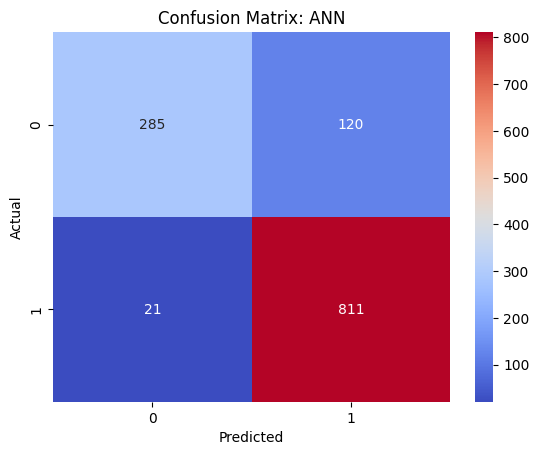

In [ ]:
y_pred_ann = (model.predict(X_test) > 0.5).astype("int32")

from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred_ann))

sns.heatmap(confusion_matrix(y_test, y_pred_ann), annot=True, fmt='d', cmap='coolwarm')
plt.title("Confusion Matrix: ANN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
import pandas as pd

df_scores = pd.DataFrame(all_scores).T
df_scores.loc["ANN"] = {
    'Accuracy': accuracy,
    'Precision': precision_score(y_test, y_pred_ann),
    'Recall': recall_score(y_test, y_pred_ann),
    'F1-Score': f1_score(y_test, y_pred_ann),
    'AUC': None  # we can compute using roc_auc_score if needed
}

df_scores = df_scores.sort_values("Accuracy", ascending=False)
df_scores.style.background_gradient(cmap='Blues').format("{:.3f}")


,Accuracy,Precision,Recall,F1-Score,AUC
Random Forest,0.958,0.955,0.984,0.969,0.986
Logistic Regression,0.952,0.963,0.966,0.965,0.970
Support Vector Machine,0.948,0.951,0.974,0.962,0.984
K-Nearest Neighbors,0.904,0.947,0.907,0.927,0.964
ANN,0.886,0.871,0.975,0.920,nan
Decision Tree,0.876,0.923,0.889,0.906,0.868
